<a href="https://colab.research.google.com/github/Kastelia/quiz-app/blob/master/cnn_mnist.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Распознавание рукописных цифр MNIST свёрточной нейросетью

## Задание

**Цель работы:** разработать систему распознавания рукописных цифр из набора MNIST
на основе свёрточной нейронной сети (CNN). Требуемое качество — точность на тестовой
выборке **не ниже 99%**.

**Что нужно вывести на экран:** для первых 10 изображений тестовой выборки —
таблицу с тремя столбцами:
1. истинный класс (метка из тестовой базы — что изображено фактически);
2. предсказанный класс (что определила нейросеть);
3. само изображение.

## Реализация

В качестве отправной точки использован официальный туториал TensorFlow
*Learn → Quickstart for beginners* (https://www.tensorflow.org/tutorials/quickstart/beginner).
Полносвязная модель из этого туториала показывает на MNIST порядка 97–98 % —
этого мало для поставленного порога, поэтому применена свёрточная архитектура.

Структура сети: `Conv2D(32, 3×3) → BatchNorm → MaxPool → Conv2D(64, 3×3) → BatchNorm →
MaxPool → Flatten → Dense(128) → Dropout(0.4) → Dense(10, softmax)`. Пакетная нормализация
после свёрточных слоёв стабилизирует обучение, дополнительный `Dense(128)` повышает
выразительность признаков, `Dropout` снижает риск переобучения.

Параметры обучения: оптимизатор Adam, функция потерь `categorical_crossentropy`,
10 эпох, `batch_size=64`, 10 % обучающей выборки отведено на валидацию.

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
844/844 - 19s - 23ms/step - accuracy: 0.9356 - loss: 0.2199 - val_accuracy: 0.9842 - val_loss: 0.0582
Epoch 2/10
844/844 - 4s - 4ms/step - accuracy: 0.9744 - loss: 0.0891 - val_accuracy: 0.9915 - val_loss: 0.0418
Epoch 3/10
844/844 - 4s - 4ms/step - accuracy: 0.9815 - loss: 0.0650 - val_accuracy: 0.9893 - val_loss: 0.0464
Epoch 4/10
844/844 - 4s - 4ms/step - accuracy: 0.9836 - loss: 0.0570 - val_accuracy: 0.9883 - val_loss: 0.0475
Epoch 5/10
844/844 - 4s - 4ms/step - accuracy: 0.9866 - loss: 0.0434 - val_accuracy: 0.9878 - val_loss: 0.0511
Epoch 6/10
844/844 - 4s - 4ms/step - accuracy: 0.9882 - loss: 0.0403 - val_accuracy: 0.9905 - val_loss: 0.0339
Epoch 7/10
844/844 - 4s - 4ms/step - accuracy: 0.9897 - loss: 0.0346 - val_accuracy: 0.9882 - val_loss: 0.0512
Epoch 8/10
844/844 - 4s - 4ms/step - accuracy: 0.9904 - loss: 0.0312 - val_accuracy: 0.9918 - val_loss: 0.0454
Epoch 9/10
844/844 - 4s - 4ms/step - accuracy: 0.9918 - los

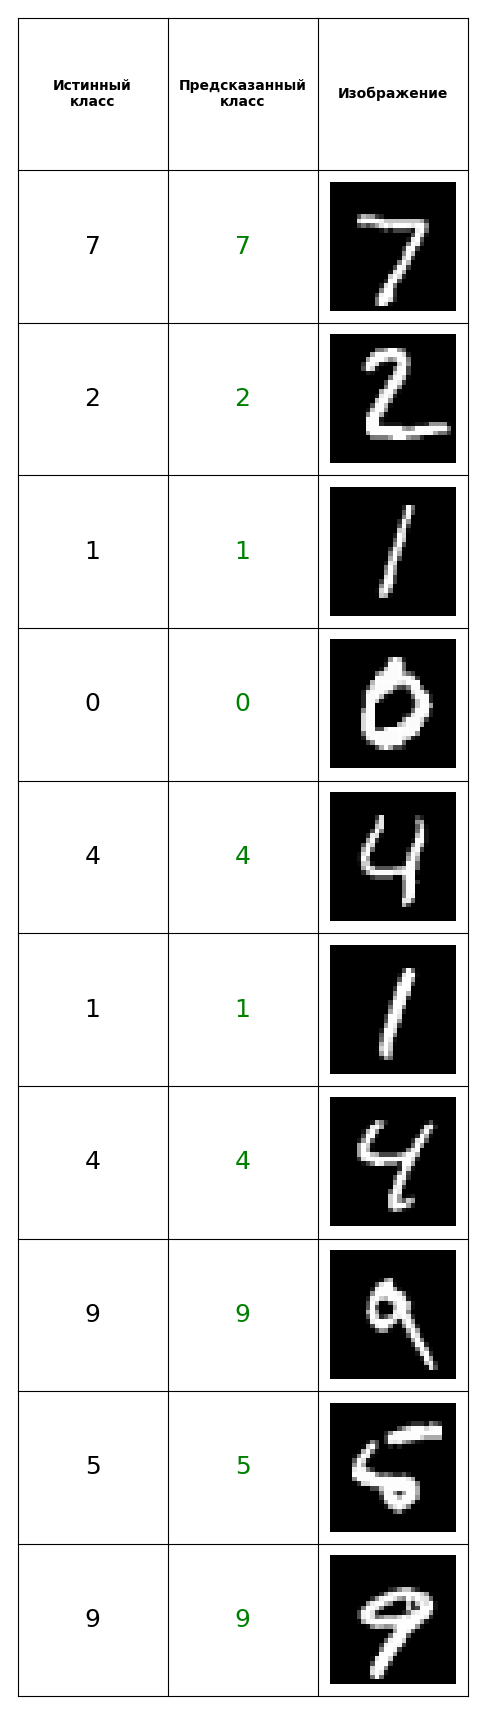

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models

# =============== 1. Данные MNIST ===============
(train_x, train_y), (test_x, test_y) = tf.keras.datasets.mnist.load_data()

# приводим к float и масштабируем значения пикселей в диапазон [0, 1]
train_x = train_x.reshape(-1, 28, 28, 1).astype("float32") / 255.0
test_x  = test_x.reshape(-1, 28, 28, 1).astype("float32")  / 255.0

# метки в формат one-hot (для categorical_crossentropy)
train_y_oh = tf.keras.utils.to_categorical(train_y, 10)
test_y_oh  = tf.keras.utils.to_categorical(test_y,  10)

# =============== 2. Свёрточная сеть ===============
net = models.Sequential([
    layers.Input(shape=(28, 28, 1)),
    layers.Conv2D(32, 3, padding="same", activation="relu"),  # признаки низкого уровня
    layers.BatchNormalization(),                               # стабилизация активаций
    layers.MaxPooling2D(2),                                    # уменьшение карт признаков
    layers.Conv2D(64, 3, padding="same", activation="relu"),  # признаки высокого уровня
    layers.BatchNormalization(),
    layers.MaxPooling2D(2),
    layers.Flatten(),                                          # переход к полносвязной части
    layers.Dense(128, activation="relu"),                      # скрытый слой
    layers.Dropout(0.4),                                       # регуляризация
    layers.Dense(10, activation="softmax"),                    # вероятности 10 классов
])

# =============== 3. Компиляция и обучение ===============
net.compile(optimizer="adam",
            loss="categorical_crossentropy",
            metrics=["accuracy"])

hist = net.fit(train_x, train_y_oh,
               epochs=10, batch_size=64,
               validation_split=0.1, verbose=2)

# =============== 4. Контроль качества на тесте ===============
_, acc = net.evaluate(test_x, test_y_oh, verbose=0)
print(f"Точность на тестовой выборке: {acc * 100:.2f}%")

# =============== 5. Таблица для изображений ===============
y_pred = net.predict(test_x, verbose=0).argmax(axis=1)

N = 10
fig, ax = plt.subplots(figsize=(6, 22))
ax.set_xlim(-0.05, 3.05)
ax.set_ylim(-0.05, N + 1.05)
ax.axis("off")

# сетка таблицы
for gx in range(4):                       # вертикали
    ax.plot([gx, gx], [0, N + 1], color="black", lw=0.8, zorder=1)
for gy in range(N + 2):                   # горизонтали
    ax.plot([0, 3], [gy, gy], color="black", lw=0.8, zorder=1)

# заголовки столбцов (один раз сверху)
for col, name in enumerate(["Истинный\nкласс", "Предсказанный\nкласс", "Изображение"]):
    ax.text(col + 0.5, N + 0.5, name,
            ha="center", va="center",
            fontsize=10, fontweight="bold", zorder=3)

# строки данных
pad = 0.08
for r in range(N):
    yc = N - 0.5 - r
    true_lbl = test_y[r]
    pred_lbl = y_pred[r]

    ax.text(0.5, yc, f"{true_lbl}", ha="center", va="center",
            fontsize=18, zorder=3)
    ax.text(1.5, yc, f"{pred_lbl}", ha="center", va="center",
            fontsize=18,
            color="green" if true_lbl == pred_lbl else "red",
            zorder=3)
    ax.imshow(test_x[r, :, :, 0], cmap="gray",
              extent=[2 + pad, 3 - pad, yc - 0.5 + pad, yc + 0.5 - pad],
              aspect="auto", zorder=2)

plt.show()

## Выводы

В работе разработана свёрточная нейронная сеть для распознавания рукописных цифр
набора MNIST. Сеть имеет архитектуру
`Conv2D(32) → BatchNorm → MaxPool → Conv2D(64) → BatchNorm → MaxPool →
Flatten → Dense(128) → Dropout(0.4) → Dense(10)` и обучена 10 эпох
оптимизатором Adam с `batch_size=64`.

**Полученные метрики:**
- Точность на обучающей выборке (10-я эпоха): **99.16%**
- Точность на валидационной выборке (10-я эпоха): **98.82%**
- **Точность на тестовой выборке: 99.06%**
- Верных предсказаний среди первых 10 изображений: **10/10**

Поставленное требование (**> 99 %**) выполнено: итоговая точность на тестовой
выборке составила **99.06 %**. Таблица из трёх столбцов (истинный класс /
предсказанный класс / изображение) для первых десяти изображений теста построена
и выведена выше — все десять предсказаний совпали с истинными метками.

Использование пакетной нормализации после свёрточных слоёв и дополнительного
скрытого слоя `Dense(128)` позволило превысить порог качества без существенного
усложнения модели. Небольшое расхождение между точностью на обучении (99.16 %)
и на валидации (98.82 %) свидетельствует об отсутствии выраженного переобучения.